In [ ]:
from data import trump_tweets
from string import punctuation

def preprocess_text(text):
    # 분석을 위해 text를 모두 소문자로 변환합니다.
    text = text.lower()
    # @와 #을 제외한 특수문자로 이루어진 문자열 symbols를 만듭니다.
    symbols = punctuation.replace('@', '').replace('#', '')

    for i in symbols:
        text = text.replace(i, "")
    text = text.split()
    return text

def analyze_text(words):
    # 키워드, 해시태그, 멘션을 저장할 리스트를 각각 생성합니다.
    keywords, hashtags, mentions = [], [], []
    for i in words:
        if i.startswith("#"):
            keywords.append(i[1:])
            hashtags.append(i[1:])
        elif i.startswith("@"):
            keywords.append(i[1:])
            mentions.append(i[1:])
        else:
            keywords.append(i)
    
    return keywords, hashtags, mentions

def filter_by_month(tweet_data, month):
    # month를 문자열로 바꾼 month_string을 선언합니다.
    # 이 때 한 자리 수는 앞에 '0'을 넣어줍니다. (ex: 1 => '01')
    month_string = '0' + str(month) if month < 10 else str(month)

    # 선택한 달의 트윗을 filtered_tweets에 저장합니다.
    filtered_tweets = []

    # 트윗의 날짜가 선택한 달에 속해 있으면 트윗의 내용을 filtered_tweets에 추가합니다.
    for i in tweet_data:
        if i[0].startswith(month_string):
            filtered_tweets.append(i[1])

    return filtered_tweets[:5]
    

print(analyze_text(preprocess_text("On my way! #Inauguration2017 https://t.co/hOuMbxGnpe")))
print(filter_by_month(trump_tweets, 3))

In [ ]:
# matplotlib의 일부인 pyplot 라이브러리를 불러옵니다.
import matplotlib.pyplot as plt

# 월별 평균 기온을 선언합니다. 수정하지 마세요.
years = [2013, 2014, 2015, 2016, 2017]
temperatures = [5, 10, 15, 20, 17]

#막대 차트를 출력합니다.   
def draw_graph():
    # 막대 그래프의 막대 위치를 결정하는 pos를 선언합니다.
    pos = range(len(years))  # [0, 1, 2, 3, 4]
    
    # 높이가 온도인 막대 그래프를 그립니다.
    # 각 막대를 가운데 정렬합니다.
    plt.bar(pos, temperatures, align='center')
    
    # 각 막대에 해당되는 연도를 표기합니다.
    plt.xticks(pos, years)

print('막대 차트를 출력합니다.')
draw_graph()

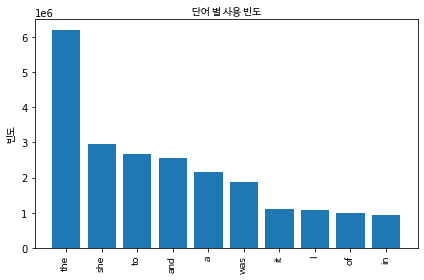

In [68]:
# 프로젝트에 필요한 패키지를 import합니다.
from operator import itemgetter
from collections import Counter
from string import punctuation
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm


def import_corpus(filename):
    # 튜플을 저장할 리스트를 생성합니다.
    corpus = []
    
    # 매개변수로 입력 받은 파일을 열고 읽습니다.
    with open(filename) as file:
        # 텍스트 파일의 각 줄을 (단어, 빈도수) 꼴로 corpus에 저장합니다.
        for line in file:
            word, freq = line.strip().split(",")
            corpus.append((word, int(freq)))
    return corpus

def create_corpus(filenames):
    # 단어를 저장할 리스트를 생성합니다.
    words = []
    
    # 여러 파일에 등장하는 모든 단어를 모두 words에 저장합니다.
    for filename in filenames:
        with open("elice/" + filename + ".txt") as file:
            content = file.read().strip()
            # 이 때 문장부호를 포함한 모든 특수기호를 제거합니다.
            # 4번째 줄에서 임포트한 punctuation을 이용하세요.
            for symbol in punctuation:
                content = content.replace(symbol, "")
            words += content.split()
    
    # words 리스트의 데이터를 corpus 형태로 변환합니다.
    corpus = Counter(words)
    return list(corpus.items())

def filter_by_prefix(corpus, prefix):
    return [(word, freq) for word, freq in corpus if word.startswith(prefix)]

def corpus_freq(corpus):
    return corpus[1]

def most_frequent_words(corpus, number):
    return sorted(corpus, key=corpus_freq, reverse=True)[:number]
    
def draw_frequency_graph(corpus):
    # 막대 그래프의 막대 위치를 결정하는 pos를 선언합니다.
    pos = range(len(corpus))
    
    # 튜플의 리스트인 corpus를 단어의 리스트 words와 빈도의 리스트 freqs로 분리합니다.
    words = [tup[0] for tup in corpus]
    freqs = [tup[1] for tup in corpus]
    
    # 한국어를 보기 좋게 표시할 수 있도록 폰트를 설정합니다.
    font = fm.FontProperties(fname='./NanumBarunGothic.ttf')
    
    # 막대의 높이가 빈도의 값이 되도록 설정합니다.
    plt.bar(pos, freqs, align='center')
    
    # 각 막대에 해당되는 단어를 입력합니다.
    plt.xticks(pos, words, rotation='vertical', fontproperties=font)
    
    # 그래프의 제목을 설정합니다.
    plt.title('단어 별 사용 빈도', fontproperties=font)
    
    # Y축에 설명을 추가합니다.
    plt.ylabel('빈도', fontproperties=font)
    
    # 단어가 잘리지 않도록 여백을 조정합니다.
    plt.tight_layout()
    
    # 그래프를 표시합니다.
    plt.savefig('graph.png')


def main(prefix=''):
    # import_corpus() 함수를 통해 튜플의 리스트를 생성합니다.
    corpus = import_corpus('corpus.txt')
    
    # head로 시작하는 단어들만 골라 냅니다.
    prefix_words = filter_by_prefix(corpus, prefix)
    
    # 주어진 prefix로 시작하는 단어들을 빈도가 높은 순으로 정렬한 뒤 앞의 10개만 추립니다.
    top_ten = most_frequent_words(prefix_words, 10)
    
    # 단어 별 빈도수를 그래프로 나타냅니다.
    draw_frequency_graph(top_ten)
    
    # 'Alice in Wonderland' 책의 단어를 corpus로 바꿉니다.
    alice_files = ["chapter1", "chapter2"]
    alice_corpus = create_corpus(alice_files)
    
    top_ten_alice = most_frequent_words(alice_corpus, 10)
    draw_frequency_graph(top_ten_alice)


if __name__ == '__main__':
    main()

# print(import_corpus("corpus.txt")[:5])
# print(create_corpus(["chapter1.txt", "chapter2.txt"])[:5])
# print(filter_by_prefix(create_corpus(["chapter1.txt", "chapter2.txt"]), "qu")[:5])
# print(most_frequent_words(create_corpus(["chapter1.txt", "chapter2.txt"]), 3)[:5])